# 🚀 Practice Day 34

**📅 Date:** 2026-10-14  
📁 Category: Phase 2 · SQL 기초(DuckDB) (Round 3/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice fundamental SQL commands (SELECT, WHERE, GROUP BY, ORDER BY, COUNT/SUM/AVG) using DuckDB on a single table
  (DuckDB로 SELECT/WHERE/GROUP BY/ORDER BY와 집계함수 등 기본 SQL 명령어를 단일 테이블에 연습)
- Find which services are booked most, how often appointments get cancelled or no-showed, and which stylist brings in the most revenue
  (어떤 서비스가 가장 많이 예약되는지, 취소·노쇼 비율은 얼마나 되는지, 어떤 스타일리스트가 매출을 가장 많이 올리는지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Willow & Co. 헤어살롱 — 예약 기록 / Willow & Co. Hair Salon — Appointment Records

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** A single table of 380 appointment records from January-May 2024. Covers 5 services (Haircut, Coloring, Perm, Styling, Treatment), 4 stylists (Jenna, Marcus, Priya, Owen), and 3 statuses (Completed, Cancelled, No-show). Prices are in USD. Cancelled/no-show appointments are recorded with price = 0. Clean — no missing values or duplicates — so the focus stays on core DuckDB SELECT/WHERE/GROUP BY/ORDER BY and aggregate functions.
(2024년 1~5월 동안의 예약 기록 380건을 담은 단일 테이블입니다. 5개 서비스(Haircut/Coloring/Perm/Styling/Treatment), 4명의 스타일리스트(Jenna/Marcus/Priya/Owen), 3가지 상태(Completed/Cancelled/No-show)를 포함합니다. 가격은 USD입니다. 취소·노쇼 건은 매출(price)이 0으로 기록됩니다. 결측치·중복 없이 깨끗한 데이터로, DuckDB의 SELECT/WHERE/GROUP BY/ORDER BY와 집계함수 연습에 초점을 둡니다.)

## Dataset Preview

In [1]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate salon appointment records ---
n = 380
services = ['Haircut', 'Coloring', 'Perm', 'Styling', 'Treatment']
service_w = [0.38, 0.22, 0.12, 0.16, 0.12]
avg_price = {'Haircut': 28, 'Coloring': 85, 'Perm': 95, 'Styling': 35, 'Treatment': 60}  # USD

stylists = ['Jenna', 'Marcus', 'Priya', 'Owen']
stylist_w = [0.30, 0.26, 0.24, 0.20]

statuses = ['Completed', 'Cancelled', 'No-show']
status_w = [0.80, 0.12, 0.08]

service_choice = rng.choice(services, size=n, p=service_w)
stylist_choice = rng.choice(stylists, size=n, p=stylist_w)
status_choice = rng.choice(statuses, size=n, p=status_w)
appt_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 150, size=n), unit='D')

price = np.array([avg_price[s] for s in service_choice]) * rng.normal(1.0, 0.08, n)
price = price.round(1)  # nearest $0.10
price = np.where(status_choice == 'Completed', price, 0)  # cancelled/no-show generate no revenue

df = pd.DataFrame({
    'appointment_id': [f'A{str(i+1).zfill(4)}' for i in range(n)],
    'service_type': service_choice,
    'stylist': stylist_choice,
    'appointment_date': appt_dates,
    'price': price,
    'status': status_choice
})
df = df.sort_values('appointment_date').reset_index(drop=True)

df.head(10)


,appointment_id,service_type,stylist,appointment_date,price,status
0,A0121,Coloring,Priya,2024-01-01,74.3,Completed
1,A0366,Coloring,Marcus,2024-01-01,73.0,Completed
2,A0162,Treatment,Marcus,2024-01-01,0.0,Cancelled
3,A0348,Haircut,Jenna,2024-01-01,27.5,Completed
4,A0036,Haircut,Jenna,2024-01-01,24.4,Completed
5,A0163,Haircut,Owen,2024-01-02,31.3,Completed
6,A0130,Coloring,Jenna,2024-01-04,83.6,Completed
7,A0356,Coloring,Priya,2024-01-04,93.0,Completed
8,A0049,Perm,Jenna,2024-01-04,88.9,Completed
9,A0219,Treatment,Owen,2024-01-05,60.3,Completed


## Dataset Information

In [2]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   appointment_id    380 non-null    str           
 1   service_type      380 non-null    str           
 2   stylist           380 non-null    str           
 3   appointment_date  380 non-null    datetime64[us]
 4   price             380 non-null    float64       
 5   status            380 non-null    str           
dtypes: datetime64[us](1), float64(1), str(4)
memory usage: 17.9 KB

Shape: (380, 6)


,appointment_id,service_type,stylist,appointment_date,price,status
count,380,380,380,380,380.000000,380
unique,380,5,4,NaN,NaN,3
top,A0121,Haircut,Jenna,NaN,NaN,Completed
freq,1,147,111,NaN,NaN,301
mean,NaN,NaN,NaN,2024-03-13 21:05:41.052631,41.245263,NaN
min,NaN,NaN,NaN,2024-01-01 00:00:00,0.000000,NaN
25%,NaN,NaN,NaN,2024-02-03 18:00:00,25.175000,NaN
50%,NaN,NaN,NaN,2024-03-10 00:00:00,30.750000,NaN
75%,NaN,NaN,NaN,2024-04-23 00:00:00,72.100000,NaN
max,NaN,NaN,NaN,2024-05-29 00:00:00,112.600000,NaN


---
# ❓ Business Questions

1. **(Analysis)** Which service type has been booked the most, and which the least?
   (어떤 서비스가 가장 많이/적게 예약되었는가?)
2. **(Analysis)** What percentage of appointments are Completed, Cancelled, or No-show?
   (전체 예약 중 완료·취소·노쇼 비율은 각각 몇 %인가?)
3. **(Analysis)** Which stylist generated the most total revenue from completed appointments, and which the least?
   (완료된 예약 기준, 어떤 스타일리스트가 매출을 가장 많이/적게 올렸는가?)
4. **(Visualization)** Compare appointment counts across all 5 service types.
   (5개 서비스의 예약건수를 비교하면?)
5. **(Visualization)** Show the breakdown of appointment status (Completed/Cancelled/No-show).
   (예약 상태(완료/취소/노쇼) 비중을 보면?)

---
# 🔍 Data Cleaning Check


In [3]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
appointment_id      0
service_type        0
stylist             0
appointment_date    0
price               0
status              0
dtype: int64

Duplicate rows: 0

Dtypes
appointment_id                 str
service_type                   str
stylist                        str
appointment_date    datetime64[us]
price                      float64
status                         str
dtype: object

Column names
['appointment_id', 'service_type', 'stylist', 'appointment_date', 'price', 'status']

Text columns — unique counts
appointment_id    380
service_type        5
stylist             4
status              3
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which service type has been booked the most, and which the least? (어떤 서비스가 가장 많이/적게 예약되었는가?)

**Result:** Haircut is highest at **147** appointments. Treatment is lowest at **39**.  
(가장 많은 서비스는 Haircut 147건, 가장 적은 서비스는 Treatment 39건)

**Insight:** Haircut is **108** above Treatment and **61** above the second place, Coloring (**86**).  
(Haircut는 Treatment보다 108건, 2위 Coloring(86건)보다 61건 많음)


In [4]:
# Question 1 (DuckDB): appointment count by service_type

import duckdb

duckdb.sql("""
    SELECT 
        service_type,
        COUNT(*) as count
    FROM df
    GROUP BY service_type
    ORDER BY count DESC
""").df()


,service_type,count
0,Haircut,147
1,Coloring,86
2,Styling,66
3,Perm,42
4,Treatment,39


## Question 2

**Question:** What percentage of appointments are Completed, Cancelled, or No-show? (완료·취소·노쇼 비율은 각각 몇 %인가?)

**Result:** Completed **301** (**79.2%**), Cancelled **44** (**11.6%**), No-show **35** (**9.2%**).  
(Completed 301건(79.2%), Cancelled 44건(11.6%), No-show 35건(9.2%))

**Insight:** Completed is **79.2%** of **380** appointments. Cancelled and No-show together are **79** appointments, **20.8%**.  
(380건 중 Completed가 79.2%. Cancelled와 No-show를 합치면 79건, 20.8%)


In [5]:
# Question 2 (DuckDB): status breakdown as a % of all appointments

duckdb.sql("""
    SELECT
        status,
        COUNT(*) AS count,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM df
    GROUP BY status
    ORDER BY pct DESC
""").df()

,status,count,pct
0,Completed,301,79.2
1,Cancelled,44,11.6
2,No-show,35,9.2


## Question 3

**Question:** Which stylist generated the most total revenue from completed appointments, and which the least? (스타일리스트별 매출 최고·최저는?)

**Result:** Marcus is highest at **$4,096.3**. Owen is lowest at **$3,655.1**.  
(가장 높은 스타일리스트는 Marcus $4,096.3, 가장 낮은 스타일리스트는 Owen $3,655.1)

**Insight:** Marcus is **$441.2** above Owen and **$72.1** above the second place, Jenna (**$4,024.2**).  
(Marcus는 Owen보다 $441.2, 2위 Jenna($4,024.2)보다 $72.1 높음)


In [6]:
# Question 3 (DuckDB): total revenue by stylist (cancelled/no-show rows already have price = 0)

duckdb.sql("""
    SELECT
        stylist,
        SUM(price) as total_revenue
    FROM df
    GROUP BY stylist
    ORDER BY total_revenue DESC
""").df()

,stylist,total_revenue
0,Marcus,4096.3
1,Jenna,4024.2
2,Priya,3897.6
3,Owen,3655.1


---
# 📈 Visualization

**Chart 1:** Bar chart — appointment count by service type (막대그래프: 서비스별 예약건수)

*Interpretation:* The bars fall from Haircut (**147**) to Coloring (**86**), Styling (**66**), Perm (**42**), and Treatment (**39**). Haircut is close to twice Coloring.  
(막대는 Haircut 147, Coloring 86, Styling 66, Perm 42, Treatment 39 순으로 짧아짐. Haircut는 Coloring의 두 배에 가까움)

---

**Chart 2:** Pie chart — appointment status breakdown (파이차트: 예약 상태 비중)

*Interpretation:* Completed is the large slice at **79.2%**. Cancelled is **11.6%** and No-show is **9.2%**.  
(Completed가 79.2%로 큰 조각. Cancelled는 11.6%, No-show는 9.2%)


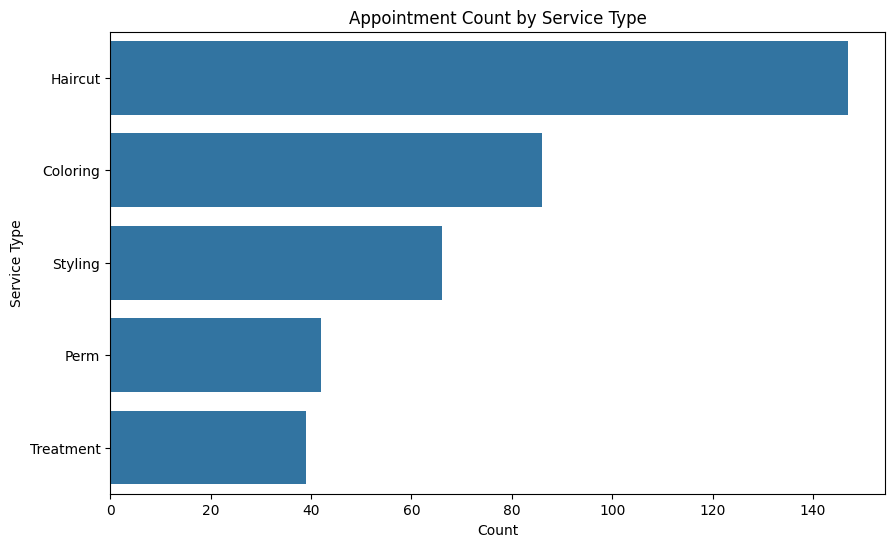

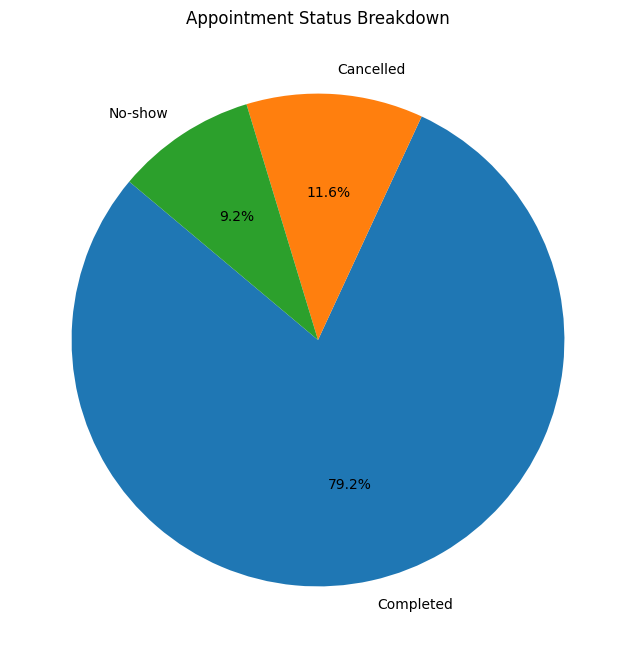

In [7]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: appointment count by service type (bar)
count_by_service = duckdb.sql("""
    SELECT 
        service_type,
        COUNT(*) as count
    FROM df
    GROUP BY service_type
    ORDER BY count DESC
""").df()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='count', y='service_type', data=count_by_service, ax=ax)
ax.set_title('Appointment Count by Service Type')
ax.set_xlabel('Count')
ax.set_ylabel('Service Type')
plt.show()

# Chart 2: appointment status breakdown (pie)
appointment_status = duckdb.sql("""
    SELECT
        status,
        COUNT(*) AS count,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM df
    GROUP BY status
    ORDER BY pct DESC
""").df()

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(appointment_status['pct'], labels=appointment_status['status'], autopct='%1.1f%%', startangle=140)
ax.set_title('Appointment Status Breakdown')
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Haircut is the most booked service at **147** of **380** appointments. Treatment is the least at **39**.  
  (380건 중 Haircut가 147건으로 가장 많고, Treatment가 39건으로 가장 적음)
- **79.2%** of appointments are Completed. Cancelled plus No-show is **20.8%** (**79** appointments).  
  (예약의 79.2%가 Completed. Cancelled와 No-show를 합치면 20.8%(79건))
- Marcus leads stylist revenue at **$4,096.3**. Owen is last at **$3,655.1**, a gap of **$441.2**.  
  (스타일리스트 매출은 Marcus가 $4,096.3으로 1위. Owen이 $3,655.1로 마지막이고 차이는 $441.2)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Staff for Haircut first. It is **147** bookings, **61** above Coloring.  
   (Haircut 인력을 먼저 두기. 147건으로 Coloring보다 61건 많음)
2. Follow up the **79** appointments that were Cancelled or No-show (**20.8%**).  
   (Cancelled 또는 No-show인 79건(20.8%)을 후속 확인하기)
3. Compare Marcus (**$4,096.3**) and Owen (**$3,655.1**) on completed work, since the gap is **$441.2**.  
   (Marcus($4,096.3)와 Owen($3,655.1)의 완료 예약을 비교하기. 차이가 $441.2)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- Q2 first counted each status and stopped, so the percentage the question asked for was missing.  
  (Q2에서 상태별 건수만 세고 멈춰서, 질문이 요구한 퍼센트가 없었음)
- I did not see why `SUM(COUNT(*)) OVER ()` needs the empty `OVER ()`.  
  (SUM(COUNT(*)) OVER ()에서 빈 OVER ()가 왜 필요한지 바로 보이지 않았음)  


---
# ✅ What I Learned
*Today's biggest lesson*

- A share inside `GROUP BY` is `COUNT(*) * 100.0 / SUM(COUNT(*)) OVER ()`. The empty `OVER ()` sums every group.  
  (GROUP BY 안의 비중은 COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (). 빈 OVER ()가 모든 그룹을 합함)
- `100.0` keeps the division from dropping the decimal, and `ROUND(..., 1)` shows one decimal place.  
  (100.0을 써야 나눗셈에서 소수가 남고, ROUND(..., 1)이 소수 한 자리를 보여줌)
- Cancelled and No-show rows already have `price = 0`, so `SUM(price)` by stylist is the completed revenue.  
  (Cancelled와 No-show 행은 price가 이미 0이라, 스타일리스트별 SUM(price)가 완료 매출)  


---
# 🧠 Reflection

**What was difficult?**  
Turning the status counts into a percentage of all appointments.  
(상태별 건수를 전체 예약 대비 퍼센트로 바꾸는 것)

**Why?**  
`COUNT(*)` is one group at a time, and the denominator has to be the sum of every group.  
(COUNT(*)는 그룹마다 하나이고, 분모는 모든 그룹의 합이어야 함)

**How did I solve it?**  
Used `SUM(COUNT(*)) OVER ()` so each row is divided by **380**.  
(SUM(COUNT(*)) OVER ()로 각 행을 380으로 나눔)

**What would I do differently next time?**  
Add the percentage column in the same query as the count, instead of stopping at `COUNT(*)`.  
(COUNT(*)에서 멈추지 않고, 같은 쿼리에 퍼센트 열을 같이 넣기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
Counts, status shares, and stylist revenue are clear. The empty `OVER ()` still needs a second look.  
(건수, 상태 비중, 스타일리스트 매출은 이해함. 빈 OVER ()는 한 번 더 봐야 함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  
The SQL totals were short. The percentage window was the hard part.  
(SQL 합계는 짧았고, 어려운 부분은 퍼센트 창 함수였음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 35 — table merge (Round 3/5)  
  (테이블 병합 복습)  
